# Wine Quality AI Analysis: Random Forest vs KNN with SHAP Explainability

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/drive/1NuY5aJ_2HAlA7Lp0iuy6ap9ZC-hOMrbo?usp=sharing)
[![Live Web App](https://img.shields.io/badge/Web_App-NeuroML_Studio-06b6d4?style=flat&logo=react)](https://saiprasanna7075-prog.github.io/neuroml-studio/)

This notebook contains the complete machine learning pipeline comparing **Random Forest** and **K-Nearest Neighbors (KNN)** on the Wine Quality dataset, featuring:
- Exploratory Data Analysis, missing value checks & deduplication
- 3-Tier Quality Target Bucketing (Low <= 4, Medium 5-6, High >= 7)
- Leak-free preprocessing & StandardScaler strictly on training partitions
- K-value hyperparameter tuning (K=1 to 15) with 5-fold cross validation
- 300-tree Balanced Random Forest Classifier
- Comprehensive Model Arena comparison (Accuracy, Precision, Recall, F1, 5-Fold CV)
- SHAP tree explainability (Summary plots, Bar plots, Waterfall single prediction)


In [ ]:
# ==========================
# Import Libraries
# ==========================
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================
# Load Dataset
# ==========================
from google.colab import files
uploaded = files.upload()

df = pd.read_csv("winequality-white.csv", sep=";")



# ==========================
# Missing Values
# ==========================
print("\nMissing Values:")
print(df.isnull().sum())

plt.figure(figsize=(10,5))
sns.heatmap(df.isnull(), cbar=False, cmap="viridis")
plt.title("Missing Values Heatmap")
plt.show()


print("\nDuplicate Rows:", df.duplicated().sum())


df = df.drop_duplicates()

print("Dataset Shape After Removing Duplicates:", df.shape)
df.hist(figsize=(18,12), bins=20)
plt.suptitle("Feature Distributions")
plt.show()

# ==========================
# Box Plot for All Features
# ==========================

plt.figure(figsize=(16,8))

sns.boxplot(data=df)

plt.title("Box Plot of All Features", fontsize=16)
plt.xlabel("Features", fontsize=12)
plt.ylabel("Values", fontsize=12)
plt.xticks(rotation=45)

plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()
# ==========================================
# Random Forest Model
# ==========================================

import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------------
# Toggle this: True = bucket quality into low/medium/high (recommended)
#              False = keep original quality scores (3-9)
# ------------------------------------------------------------------
USE_BUCKETED_TARGET = True

# Separate Features and Target
X = df.drop("quality", axis=1)

if USE_BUCKETED_TARGET:
    def quality_to_label(q):
        if q <= 4:
            return "low"
        elif q <= 6:
            return "medium"
        else:
            return "high"

    y = df["quality"].apply(quality_to_label)
else:
    y = df["quality"]

print("Class distribution:\n", y.value_counts(), "\n")

# Train-Test Split (70:30) - stratified so rare classes appear in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)
print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

# Create Random Forest Model
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42
)

# Cross-validation on training data (sanity check before final fit)
cv_scores = cross_val_score(rf_model, X_train, y_train, cv=5)
print(f"\n5-Fold CV Accuracy: {cv_scores.mean()*100:.2f}% (+/- {cv_scores.std()*100:.2f}%)")



In [1]:
# Train the Model
rf_model.fit(X_train, y_train)

# Prediction
y_pred = rf_model.predict(X_test)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"\nRandom Forest Test Accuracy: {accuracy*100:.2f}%")

# Classification Report
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

# Confusion Matrix
labels = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# Feature Importance
importance = rf_model.feature_importances_
feature_importance = (
    pd.DataFrame({
        'Feature': X.columns,
        'Importance': importance
    })
    .sort_values(by='Importance', ascending=False)
)
print("\nFeature Importance:")
print(feature_importance)

# Feature Importance Graph
plt.figure(figsize=(10, 6))
sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------
# SHAP Explainability
# ------------------------------------------------------------------
import shap

# TreeExplainer is optimized for tree-based models like Random Forest
explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_test)

# --- 1. Global Summary Plot ---
# Shows which features matter most overall, and whether high/low
# values of each feature push predictions up or down, per class.
shap.summary_plot(shap_values, X_test, class_names=rf_model.classes_)

# --- 2. Bar Summary Plot (mean absolute SHAP value per feature) ---
# Similar to feature_importances_ but derived from SHAP - more reliable.
shap.summary_plot(shap_values, X_test, plot_type="bar", class_names=rf_model.classes_)

# --- 3. Explain a single prediction (waterfall plot) ---
# Pick one sample from the test set to explain in detail
sample_idx = 0
class_idx = list(rf_model.classes_).index(y_pred[sample_idx])

explanation = shap.Explanation(
    values=shap_values[class_idx][sample_idx]
        if isinstance(shap_values, list)
        else shap_values[sample_idx, :, class_idx],
    base_values=explainer.expected_value[class_idx],
    data=X_test.iloc[sample_idx],
    feature_names=X_test.columns.tolist()
)

plt.figure()
shap.plots.waterfall(explanation, show=True)

print(f"\nExplained sample index {sample_idx} | "
      f"Predicted: {y_pred[sample_idx]} | Actual: {y_test.iloc[sample_idx]}")

NameError: name 'rf_model' is not defined

Feature scaling completed!
Scaled Training Shape: (2772, 11)
Scaled Testing Shape: (1189, 11)


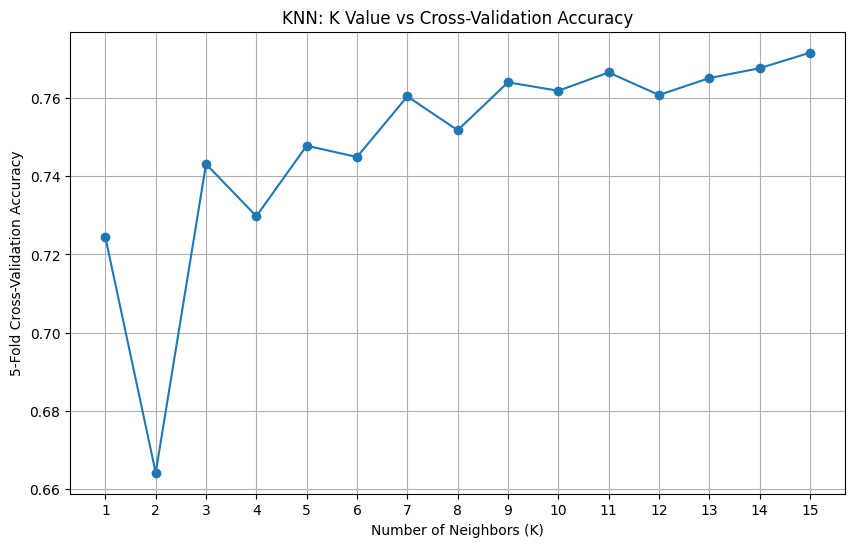


Best K value: 15
Best 5-Fold CV Accuracy: 77.16 %

KNN model trained successfully!

KNN MODEL PERFORMANCE
Best K: 15
Accuracy : 78.47 %
Precision: 77.88 %
Recall   : 78.47 %
F1 Score : 75.0 %

KNN Classification Report:

              precision    recall  f1-score   support

        high       0.65      0.37      0.47       248
         low       1.00      0.04      0.07        52
      medium       0.80      0.94      0.87       889

    accuracy                           0.78      1189
   macro avg       0.82      0.45      0.47      1189
weighted avg       0.78      0.78      0.75      1189



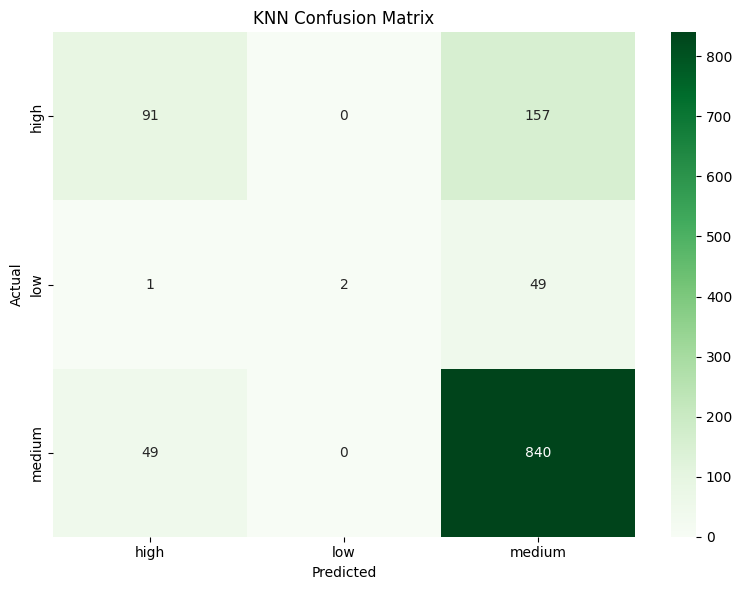


RANDOM FOREST vs KNN
        Model  Test Accuracy  Precision  Recall  F1 Score  5-Fold CV Accuracy
Random Forest          79.06      77.67   79.06     76.91               78.28
          KNN          78.47      77.88   78.47     75.00               77.16


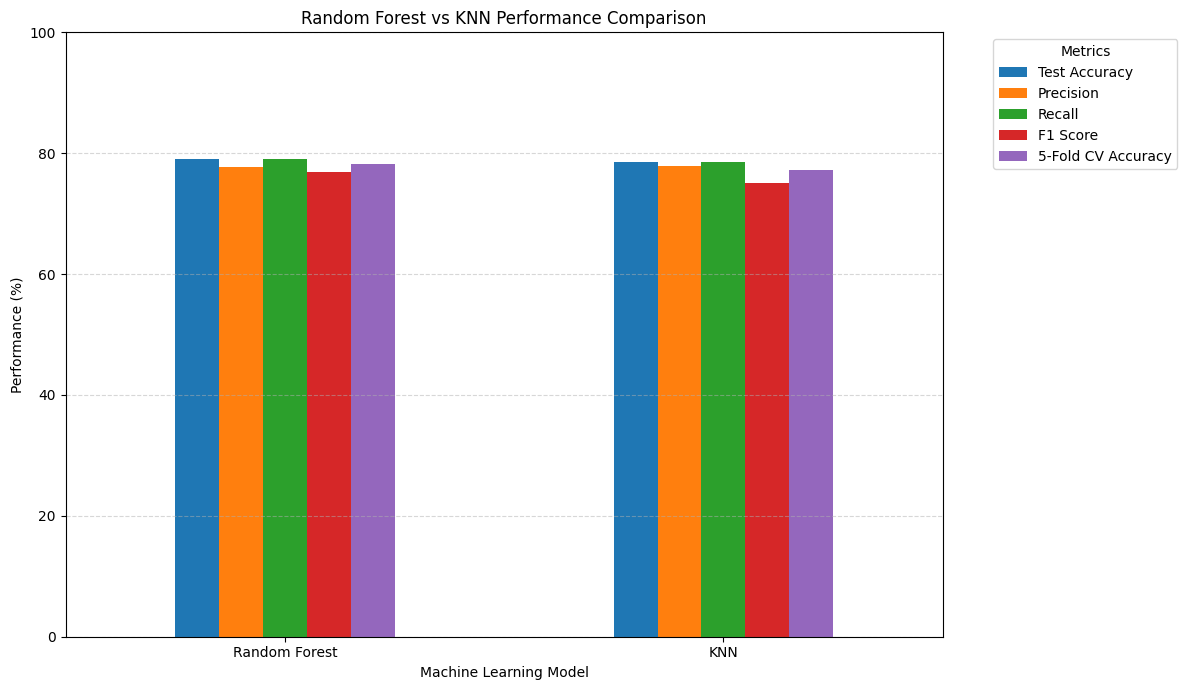

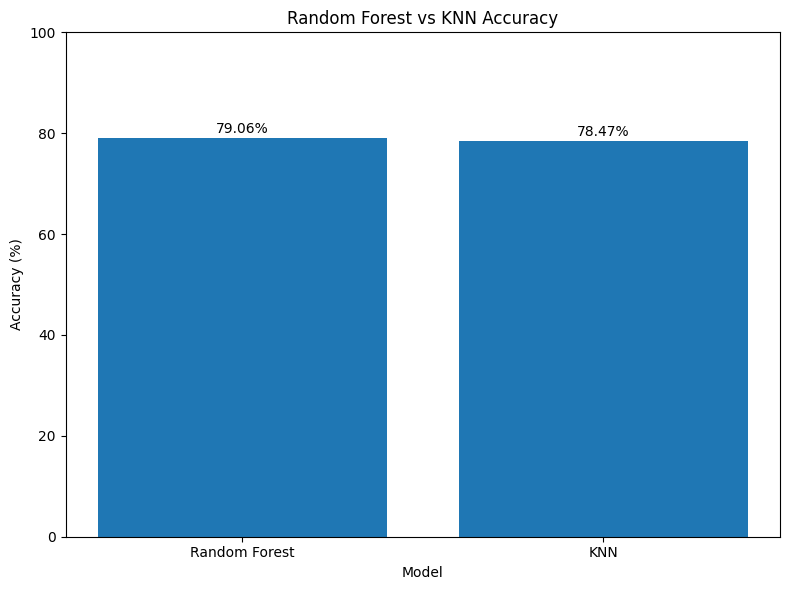


🏆 Best Test Accuracy: Random Forest

FINAL PROJECT SUMMARY

Random Forest:
Test Accuracy      : 79.06 %
5-Fold CV Accuracy : 78.28 %
Precision          : 77.67 %
Recall             : 79.06 %
F1 Score           : 76.91 %

KNN:
Best K             : 15
Test Accuracy      : 78.47 %
5-Fold CV Accuracy : 77.16 %
Precision          : 77.88 %
Recall             : 78.47 %
F1 Score           : 75.0 %


In [ ]:
# ============================================================
# KNN MODEL + RANDOM FOREST vs KNN COMPARISON
# ============================================================

# ------------------------------------------------------------
# 1. Import Libraries
# ------------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)


# ============================================================
# 2. FEATURE SCALING FOR KNN
# ============================================================

# KNN is distance-based, so scaling is important.

scaler = StandardScaler()

# Fit scaler only on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform test data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")
print("Scaled Training Shape:", X_train_scaled.shape)
print("Scaled Testing Shape:", X_test_scaled.shape)


# ============================================================
# 3. FIND THE BEST K VALUE
# ============================================================

k_values = range(1, 16)

k_scores = []

for k in k_values:

    knn_temp = KNeighborsClassifier(n_neighbors=k)

    scores = cross_val_score(
        knn_temp,
        X_train_scaled,
        y_train,
        cv=5,
        scoring="accuracy"
    )

    k_scores.append(scores.mean())


# ============================================================
# 4. DISPLAY K VS ACCURACY
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    k_values,
    k_scores,
    marker="o"
)

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("5-Fold Cross-Validation Accuracy")

plt.title("KNN: K Value vs Cross-Validation Accuracy")

plt.xticks(list(k_values))

plt.grid(True)

plt.show()


# ============================================================
# 5. SELECT BEST K
# ============================================================

best_k = k_values[np.argmax(k_scores)]

print("\nBest K value:", best_k)

print(
    "Best 5-Fold CV Accuracy:",
    round(max(k_scores) * 100, 2),
    "%"
)


# ============================================================
# 6. CREATE FINAL KNN MODEL
# ============================================================

knn_model = KNeighborsClassifier(
    n_neighbors=best_k
)

# Train KNN
knn_model.fit(
    X_train_scaled,
    y_train
)

print("\nKNN model trained successfully!")


# ============================================================
# 7. KNN PREDICTION
# ============================================================

knn_pred = knn_model.predict(X_test_scaled)


# ============================================================
# 8. KNN EVALUATION
# ============================================================

knn_accuracy = accuracy_score(
    y_test,
    knn_pred
)

knn_precision = precision_score(
    y_test,
    knn_pred,
    average="weighted"
)

knn_recall = recall_score(
    y_test,
    knn_pred,
    average="weighted"
)

knn_f1 = f1_score(
    y_test,
    knn_pred,
    average="weighted"
)


print("\n================================================")
print("KNN MODEL PERFORMANCE")
print("================================================")

print("Best K:", best_k)

print("Accuracy :", round(knn_accuracy * 100, 2), "%")

print("Precision:", round(knn_precision * 100, 2), "%")

print("Recall   :", round(knn_recall * 100, 2), "%")

print("F1 Score :", round(knn_f1 * 100, 2), "%")


# ============================================================
# 9. KNN CLASSIFICATION REPORT
# ============================================================

print("\nKNN Classification Report:\n")

print(
    classification_report(
        y_test,
        knn_pred
    )
)


# ============================================================
# 10. KNN CONFUSION MATRIX
# ============================================================

labels = sorted(y.unique())

knn_cm = confusion_matrix(
    y_test,
    knn_pred,
    labels=labels
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    knn_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("KNN Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.tight_layout()

plt.show()


# ============================================================
# 11. RANDOM FOREST PERFORMANCE
# ============================================================

rf_accuracy = accuracy_score(
    y_test,
    y_pred
)

rf_precision = precision_score(
    y_test,
    y_pred,
    average="weighted"
)

rf_recall = recall_score(
    y_test,
    y_pred,
    average="weighted"
)

rf_f1 = f1_score(
    y_test,
    y_pred,
    average="weighted"
)


# ============================================================
# 12. 5-FOLD CROSS VALIDATION FOR RANDOM FOREST
# ============================================================

rf_cv_scores = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

rf_cv_accuracy = rf_cv_scores.mean()


# ============================================================
# 13. 5-FOLD CROSS VALIDATION FOR KNN
# ============================================================

knn_cv_scores = cross_val_score(
    knn_model,
    X_train_scaled,
    y_train,
    cv=5,
    scoring="accuracy"
)

knn_cv_accuracy = knn_cv_scores.mean()


# ============================================================
# 14. FINAL MODEL COMPARISON
# ============================================================

comparison = pd.DataFrame({

    "Model": [
        "Random Forest",
        "KNN"
    ],

    "Test Accuracy": [
        rf_accuracy,
        knn_accuracy
    ],

    "Precision": [
        rf_precision,
        knn_precision
    ],

    "Recall": [
        rf_recall,
        knn_recall
    ],

    "F1 Score": [
        rf_f1,
        knn_f1
    ],

    "5-Fold CV Accuracy": [
        rf_cv_accuracy,
        knn_cv_accuracy
    ]
})


# Convert scores to percentage

percentage_columns = [
    "Test Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "5-Fold CV Accuracy"
]

comparison[percentage_columns] = (
    comparison[percentage_columns] * 100
).round(2)


print("\n================================================")
print("RANDOM FOREST vs KNN")
print("================================================")

print(comparison.to_string(index=False))


# ============================================================
# 15. COMPARISON BAR GRAPH
# ============================================================

comparison_plot = comparison.set_index("Model")

comparison_plot[
    [
        "Test Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "5-Fold CV Accuracy"
    ]
].plot(
    kind="bar",
    figsize=(12, 7)
)

plt.title("Random Forest vs KNN Performance Comparison")

plt.xlabel("Machine Learning Model")

plt.ylabel("Performance (%)")

plt.xticks(rotation=0)

plt.ylim(0, 100)

plt.legend(
    title="Metrics",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.5
)

plt.tight_layout()

plt.show()


# ============================================================
# 16. ACCURACY-ONLY COMPARISON
# ============================================================

plt.figure(figsize=(8, 6))

models = [
    "Random Forest",
    "KNN"
]

accuracies = [
    rf_accuracy * 100,
    knn_accuracy * 100
]

bars = plt.bar(
    models,
    accuracies
)

plt.title("Random Forest vs KNN Accuracy")

plt.xlabel("Model")

plt.ylabel("Accuracy (%)")

plt.ylim(0, 100)

# Display accuracy above bars

for bar, value in zip(bars, accuracies):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()

plt.show()


# ============================================================
# 17. DETERMINE BEST MODEL
# ============================================================

if rf_accuracy > knn_accuracy:

    print("\n🏆 Best Test Accuracy: Random Forest")

elif knn_accuracy > rf_accuracy:

    print("\n🏆 Best Test Accuracy: KNN")

else:

    print("\n🏆 Both models have the same test accuracy!")


# ============================================================
# 18. FINAL SUMMARY
# ============================================================

print("\n================================================")
print("FINAL PROJECT SUMMARY")
print("================================================")

print("\nRandom Forest:")
print("Test Accuracy      :", round(rf_accuracy * 100, 2), "%")
print("5-Fold CV Accuracy :", round(rf_cv_accuracy * 100, 2), "%")
print("Precision          :", round(rf_precision * 100, 2), "%")
print("Recall             :", round(rf_recall * 100, 2), "%")
print("F1 Score           :", round(rf_f1 * 100, 2), "%")

print("\nKNN:")
print("Best K             :", best_k)
print("Test Accuracy      :", round(knn_accuracy * 100, 2), "%")
print("5-Fold CV Accuracy :", round(knn_cv_accuracy * 100, 2), "%")
print("Precision          :", round(knn_precision * 100, 2), "%")
print("Recall             :", round(knn_recall * 100, 2), "%")
print("F1 Score           :", round(knn_f1 * 100, 2), "%")